Import libraries

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

paths and load the dataset

In [2]:
SOURCE_FILE = Path("sierraleone-bumbuna.csv")
OUTPUT_DATA_DIR = Path("data")
OUTPUT_TABLE_DIR = Path("reports") / "tables"
OUTPUT_FIGURE_DIR = Path("reports") / "figures"

OUTPUT_DATA_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_TABLE_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_FIGURE_DIR.mkdir(parents=True, exist_ok=True)

if not SOURCE_FILE.exists():
    # Helpful fallbacks for the usual project layout.
    candidates = [
        Path("..") / "data" / "sierraleone-bumbuna.csv",
        Path("data") / "sierraleone-bumbuna.csv",
        Path("..") / "sierraleone-bumbuna.csv",
    ]
    SOURCE_FILE = next((p for p in candidates if p.exists()), SOURCE_FILE)

if not SOURCE_FILE.exists():
    raise FileNotFoundError(
        f"Could not find sierraleone-bumbuna.csv. Put it beside this notebook or in ../data/."
    )

df_raw = pd.read_csv(SOURCE_FILE)
print("Country: Sierra Leone")
print("Source:", SOURCE_FILE.resolve())
print("Shape:", df_raw.shape)
display(df_raw.head())

Country: Sierra Leone
Source: C:\Users\USED\Desktop\10 Academy\week 1\solar-challenge-week-1\data\sierraleone-bumbuna.csv
Shape: (525600, 19)


,Timestamp,GHI,DNI,DHI,ModA,ModB,Tamb,RH,WS,WSgust,WSstdev,WD,WDstdev,BP,Cleaning,Precipitation,TModA,TModB,Comments
0,2021-10-30 00:01,-0.7,-0.1,-0.8,0.0,0.0,21.9,99.1,0.0,0.0,0.0,0.0,0.0,1002,0,0.0,22.3,22.6,NaN
1,2021-10-30 00:02,-0.7,-0.1,-0.8,0.0,0.0,21.9,99.2,0.0,0.0,0.0,0.0,0.0,1002,0,0.0,22.3,22.6,NaN
2,2021-10-30 00:03,-0.7,-0.1,-0.8,0.0,0.0,21.9,99.2,0.0,0.0,0.0,0.0,0.0,1002,0,0.0,22.3,22.6,NaN
3,2021-10-30 00:04,-0.7,0.0,-0.8,0.0,0.0,21.9,99.3,0.0,0.0,0.0,0.0,0.0,1002,0,0.1,22.3,22.6,NaN
4,2021-10-30 00:05,-0.7,-0.1,-0.8,0.0,0.0,21.9,99.3,0.0,0.0,0.0,0.0,0.0,1002,0,0.0,22.3,22.6,NaN


Inspect columns, data types, and timestamps

In [3]:
print("Column names:")
print(df_raw.columns.tolist())

print("\nData types and non-null counts:")
df_raw.info()

if "Timestamp" not in df_raw.columns:
    raise KeyError("The dataset must contain a Timestamp column.")

df = df_raw.copy()
df["Timestamp"] = pd.to_datetime(df["Timestamp"], errors="coerce")
bad_timestamps = int(df["Timestamp"].isna().sum())
df = df.sort_values("Timestamp").reset_index(drop=True)

print("\nInvalid/missing timestamps:", bad_timestamps)
print("Time range:", df["Timestamp"].min(), "to", df["Timestamp"].max())
print("Duplicate rows:", int(df.duplicated().sum()))
print("Duplicate timestamps:", int(df["Timestamp"].duplicated().sum()))

Column names:
['Timestamp', 'GHI', 'DNI', 'DHI', 'ModA', 'ModB', 'Tamb', 'RH', 'WS', 'WSgust', 'WSstdev', 'WD', 'WDstdev', 'BP', 'Cleaning', 'Precipitation', 'TModA', 'TModB', 'Comments']

Data types and non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 525600 entries, 0 to 525599
Data columns (total 19 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   Timestamp      525600 non-null  str    
 1   GHI            525600 non-null  float64
 2   DNI            525600 non-null  float64
 3   DHI            525600 non-null  float64
 4   ModA           525600 non-null  float64
 5   ModB           525600 non-null  float64
 6   Tamb           525600 non-null  float64
 7   RH             525600 non-null  float64
 8   WS             525600 non-null  float64
 9   WSgust         525600 non-null  float64
 10  WSstdev        525600 non-null  float64
 11  WD             525600 non-null  float64
 12  WDstdev        525600 non-null  float64
 13 

Summary statistics and missing-value report

In [4]:
# Required by the challenge: describe all numeric columns.
display(df.describe().T)

missing_report = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(3),
}).sort_values("missing_percent", ascending=False)

display(missing_report)
print("Columns with more than 5% missing values:")
display(missing_report[missing_report["missing_percent"] > 5])

missing_report.to_csv(
    OUTPUT_TABLE_DIR / "sierraleone_missing_value_report.csv",
    index=True
)
df.describe().T.to_csv(
    OUTPUT_TABLE_DIR / "sierraleone_summary_statistics.csv",
    index=True
)

,count,mean,min,25%,50%,75%,max,std
Timestamp,525600,2022-04-30 12:00:30,2021-10-30 00:01:00,2022-01-29 06:00:45,2022-04-30 12:00:30,2022-07-30 18:00:15,2022-10-30 00:00:00,NaN
GHI,525600.0,201.957515,-19.5,-2.8,0.3,362.4,1499.0,298.49515
DNI,525600.0,116.376337,-7.8,-0.3,-0.1,107.0,946.0,218.652659
DHI,525600.0,113.720571,-17.9,-3.8,-0.1,224.7,892.0,158.946032
ModA,525600.0,206.643095,0.0,0.0,3.6,359.5,1507.0,300.896893
ModB,525600.0,198.114691,0.0,0.0,3.4,345.4,1473.0,288.889073
Tamb,525600.0,26.319394,12.3,23.1,25.3,29.4,39.9,4.398605
RH,525600.0,79.448857,9.9,68.7,85.4,96.7,100.0,20.520775
WS,525600.0,1.146113,0.0,0.0,0.8,2.0,19.2,1.239248
WSgust,525600.0,1.691606,0.0,0.0,1.6,2.6,23.9,1.617053


,missing_count,missing_percent
Comments,525600,100.0
GHI,0,0.0
Timestamp,0,0.0
DNI,0,0.0
DHI,0,0.0
ModB,0,0.0
ModA,0,0.0
RH,0,0.0
WS,0,0.0
WSgust,0,0.0


Columns with more than 5% missing values:


,missing_count,missing_percent
Comments,525600,100.0


Detect outliers with Z-scores

In [5]:
# Required columns specified in the challenge.
zscore_columns = ["GHI", "DNI", "DHI", "ModA", "ModB", "WS", "WSgust"]
available_zscore_columns = [c for c in zscore_columns if c in df.columns]
missing_zscore_columns = sorted(set(zscore_columns) - set(available_zscore_columns))
if missing_zscore_columns:
    print("Warning: columns not found and skipped:", missing_zscore_columns)

df_flagged = df.copy()
outlier_rows = []

for col in available_zscore_columns:
    values = pd.to_numeric(df_flagged[col], errors="coerce")
    std = values.std()
    if pd.notna(std) and std > 0:
        z = (values - values.mean()) / std
    else:
        z = pd.Series(np.nan, index=values.index)

    df_flagged[f"{col}_zscore"] = z
    df_flagged[f"{col}_outlier_flag"] = z.abs() > 3
    outlier_rows.append({
        "column": col,
        "threshold": "|Z| > 3",
        "outlier_count": int((z.abs() > 3).sum()),
        "outlier_percent": round(float((z.abs() > 3).mean() * 100), 4),
    })

outlier_report = pd.DataFrame(outlier_rows)
display(outlier_report)
outlier_report.to_csv(
    OUTPUT_TABLE_DIR / "sierraleone_zscore_outlier_report.csv",
    index=False
)

,column,threshold,outlier_count,outlier_percent
0,GHI,|Z| > 3,2477,0.4713
1,DNI,|Z| > 3,7586,1.4433
2,DHI,|Z| > 3,2986,0.5681
3,ModA,|Z| > 3,1604,0.3052
4,ModB,|Z| > 3,2041,0.3883
5,WS,|Z| > 3,3967,0.7548
6,WSgust,|Z| > 3,3665,0.6973


Basic cleaning and export the cleaned dataset

In [6]:
# Keep the raw data intact. Impute missing values in key numeric columns with medians.
# Outlier flags are retained for review rather than automatically dropping observations.
key_numeric_columns = [
    "GHI", "DNI", "DHI", "ModA", "ModB", "WS", "WSgust"
]
df_clean = df_flagged.copy()
imputation_rows = []

for col in key_numeric_columns:
    if col not in df_clean.columns:
        continue
    df_clean[col] = pd.to_numeric(df_clean[col], errors="coerce")
    missing_before = int(df_clean[col].isna().sum())
    median_value = df_clean[col].median()
    if missing_before > 0 and pd.notna(median_value):
        df_clean[col] = df_clean[col].fillna(median_value)
    imputation_rows.append({
        "column": col,
        "missing_before": missing_before,
        "median_used": median_value,
        "missing_after": int(df_clean[col].isna().sum()),
    })

imputation_report = pd.DataFrame(imputation_rows)
display(imputation_report)
imputation_report.to_csv(
    OUTPUT_TABLE_DIR / "sierraleone_imputation_report.csv",
    index=False
)

clean_path = OUTPUT_DATA_DIR / "sierraleone_clean.csv"
df_clean.to_csv(clean_path, index=False)
print("Cleaned dataset saved to:", clean_path.resolve())
print("Cleaned shape:", df_clean.shape)

,column,missing_before,median_used,missing_after
0,GHI,0,0.3,0
1,DNI,0,-0.1,0
2,DHI,0,-0.1,0
3,ModA,0,3.6,0
4,ModB,0,3.4,0
5,WS,0,0.8,0
6,WSgust,0,1.6,0


Cleaned dataset saved to: C:\Users\USED\Desktop\10 Academy\week 1\solar-challenge-week-1\notebooks\data\sierraleone_clean.csv
Cleaned shape: (525600, 33)


Time-series analysis: GHI, DNI, DHI, and Tamb

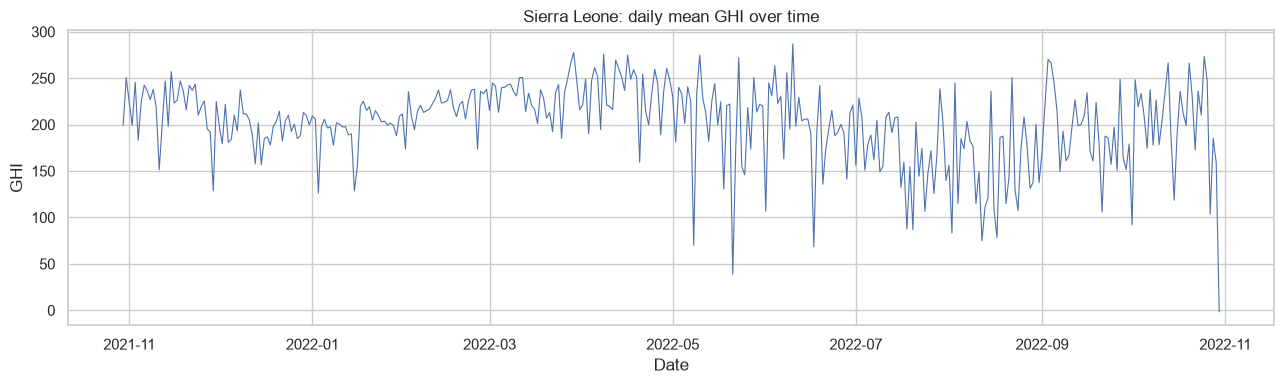

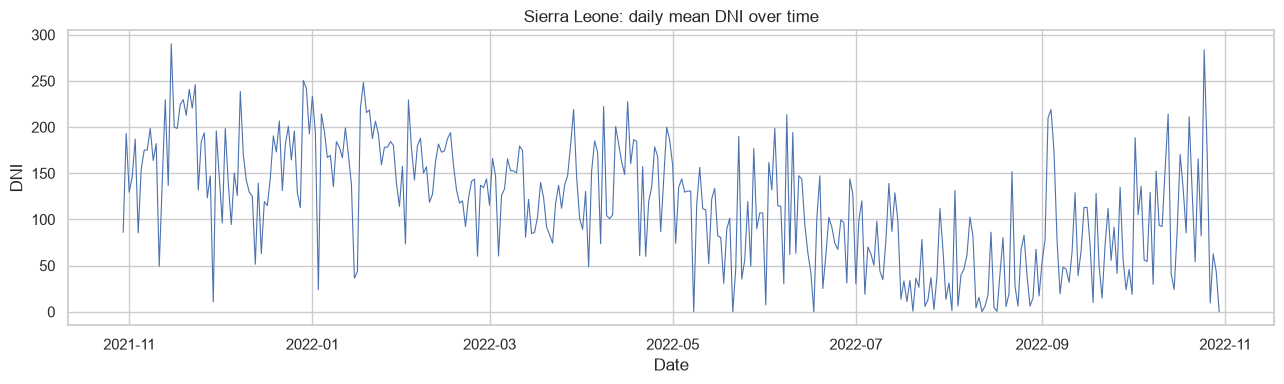

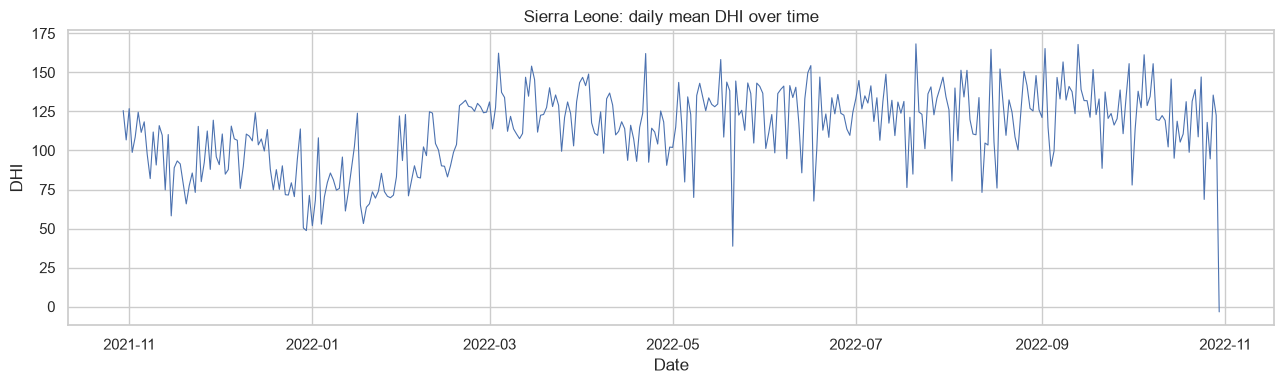

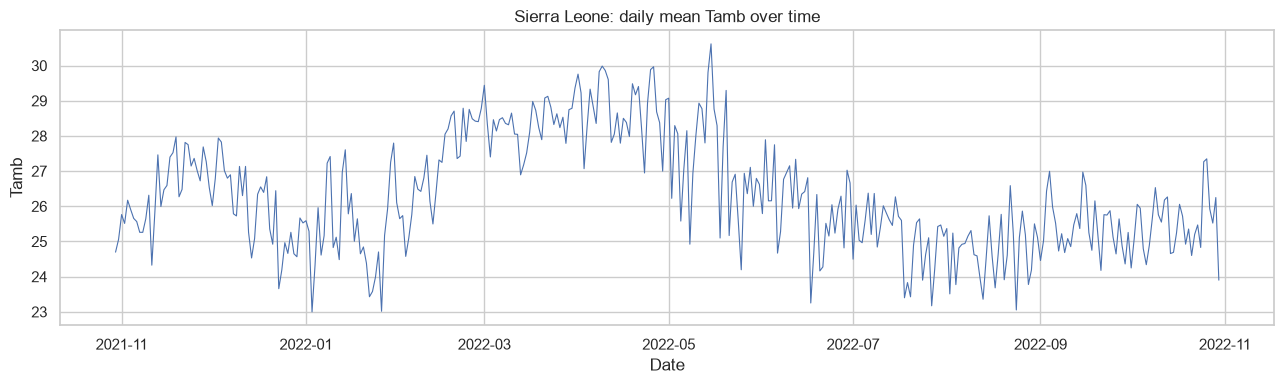

In [7]:
time_series_columns = ["GHI", "DNI", "DHI", "Tamb"]
for col in time_series_columns:
    if col not in df_clean.columns:
        print(f"Skipping {col}: column not present.")
        continue

    # Daily means reduce visual clutter for minute-level observations.
    daily_mean = df_clean.set_index("Timestamp")[col].resample("D").mean()
    plt.figure(figsize=(13, 4))
    plt.plot(daily_mean.index, daily_mean.values, linewidth=0.8)
    plt.title(f"Sierra Leone: daily mean {col} over time")
    plt.xlabel("Date")
    plt.ylabel(col)
    plt.tight_layout()
    plt.savefig(OUTPUT_FIGURE_DIR / ("sierraleone_" + col.lower() + "_daily_timeseries.png"), dpi=140)
    plt.show()

Monthly patterns

,GHI,DNI,DHI,Tamb
Timestamp,,,,
2021-10-01,224.91,139.61,116.17,24.88
2021-11-01,218.72,173.40,96.59,26.49
2021-12-01,196.44,153.59,91.32,25.88
2022-01-01,196.85,168.75,78.31,25.33
2022-02-01,219.72,147.17,107.79,27.19
2022-03-01,231.27,129.40,126.95,28.36
2022-04-01,236.64,144.40,117.43,28.75
2022-05-01,203.38,98.97,123.98,27.28
2022-06-01,200.21,98.43,121.72,25.96


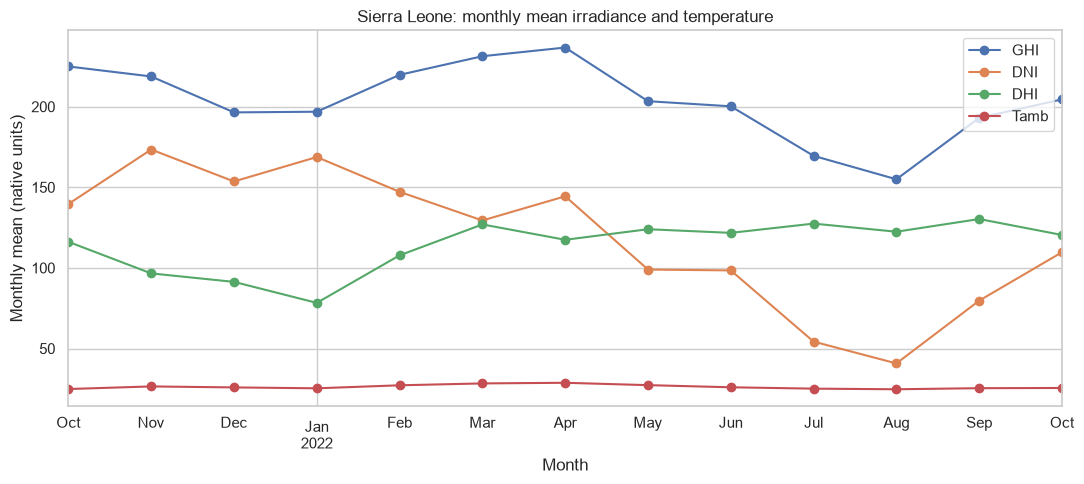

In [8]:
monthly_columns = [c for c in ["GHI", "DNI", "DHI", "Tamb"] if c in df_clean.columns]
monthly_means = df_clean.set_index("Timestamp")[monthly_columns].resample("MS").mean()
display(monthly_means.round(2))
monthly_means.to_csv(OUTPUT_TABLE_DIR / "sierraleone_monthly_means.csv")

ax = monthly_means.plot(marker="o", figsize=(11, 5))
ax.set_title("Sierra Leone: monthly mean irradiance and temperature")
ax.set_xlabel("Month")
ax.set_ylabel("Monthly mean (native units)")
plt.tight_layout()
plt.savefig(OUTPUT_FIGURE_DIR / "sierraleone_monthly_patterns.png", dpi=140)
plt.show()

Cleaning impact on ModA and ModB

,ModA,ModB
Cleaning,,
0,206.578599,198.038150
1,273.309252,277.231102


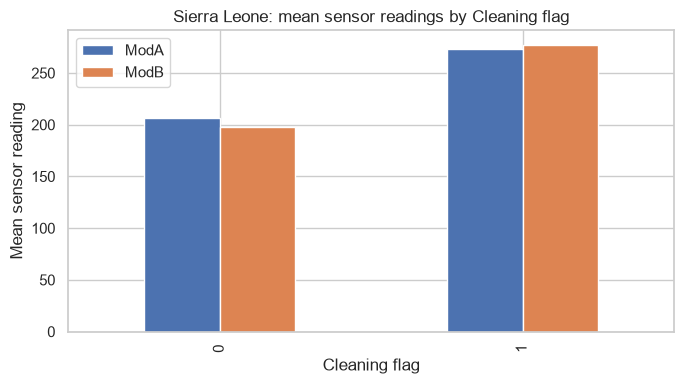

In [9]:
if "Cleaning" in df_clean.columns:
    sensor_columns = [c for c in ["ModA", "ModB"] if c in df_clean.columns]
    cleaning_means = df_clean.groupby("Cleaning", dropna=False)[sensor_columns].mean()
    display(cleaning_means)
    cleaning_means.to_csv(OUTPUT_TABLE_DIR / "sierraleone_cleaning_impact.csv")

    ax = cleaning_means.plot(kind="bar", figsize=(7, 4))
    ax.set_title("Sierra Leone: mean sensor readings by Cleaning flag")
    ax.set_xlabel("Cleaning flag")
    ax.set_ylabel("Mean sensor reading")
    plt.tight_layout()
    plt.savefig(OUTPUT_FIGURE_DIR / "sierraleone_cleaning_impact.png", dpi=140)
    plt.show()
else:
    print("Cleaning column is not present; cleaning-impact analysis skipped.")

Correlation heatmap

,GHI,DNI,DHI,TModA,TModB
GHI,1.000,0.869,0.866,0.923,0.912
DNI,0.869,1.000,0.537,0.816,0.808
DHI,0.866,0.537,1.000,0.808,0.808
TModA,0.923,0.816,0.808,1.000,0.993
TModB,0.912,0.808,0.808,0.993,1.000


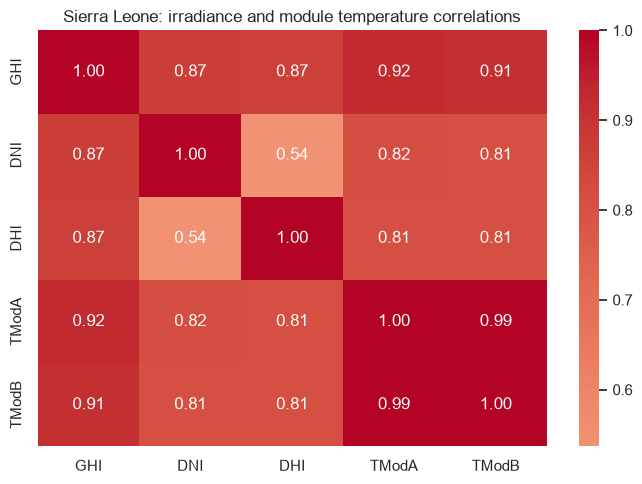

In [10]:
correlation_columns = [c for c in ["GHI", "DNI", "DHI", "TModA", "TModB"] if c in df_clean.columns]
correlation_matrix = df_clean[correlation_columns].corr(numeric_only=True)
display(correlation_matrix.round(3))
correlation_matrix.to_csv(OUTPUT_TABLE_DIR / "sierraleone_correlation_matrix.csv")

plt.figure(figsize=(7, 5))
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Sierra Leone: irradiance and module temperature correlations")
plt.tight_layout()
plt.savefig(OUTPUT_FIGURE_DIR / "sierraleone_correlation_heatmap.png", dpi=140)
plt.show()

Scatterplots: wind and humidity relationships

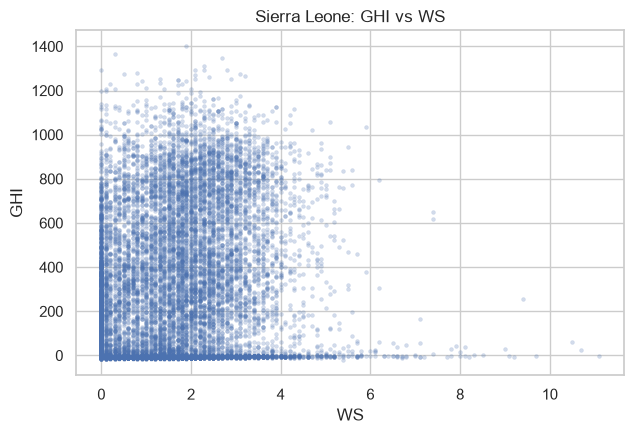

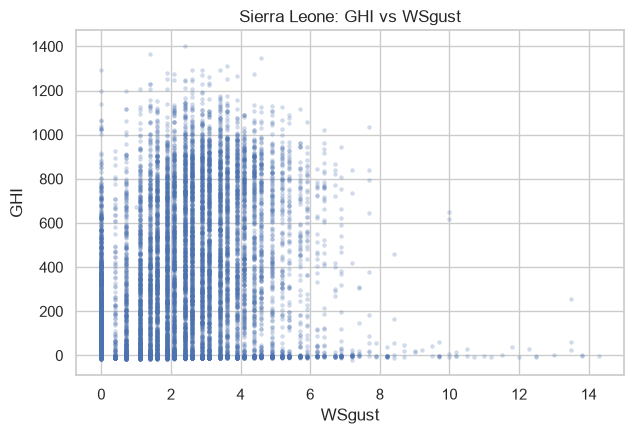

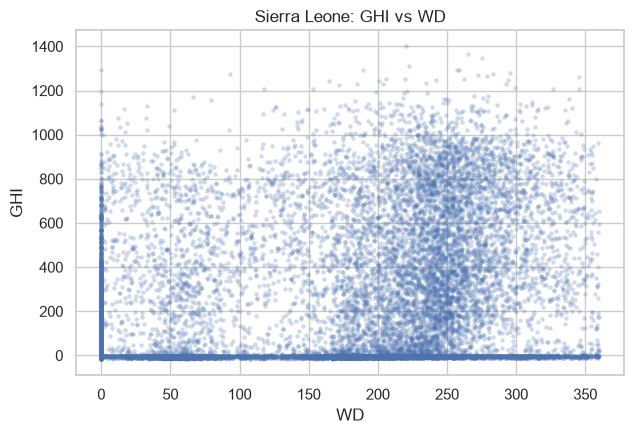

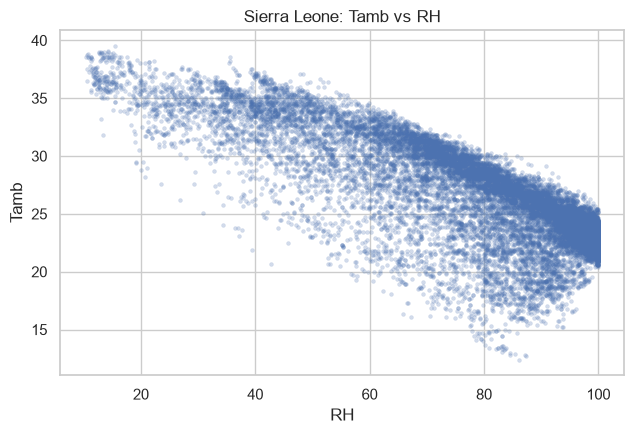

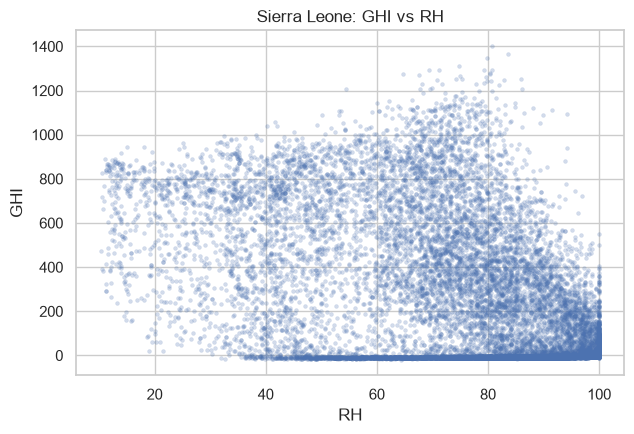

In [11]:
scatter_pairs = [
    ("WS", "GHI"),
    ("WSgust", "GHI"),
    ("WD", "GHI"),
    ("RH", "Tamb"),
    ("RH", "GHI"),
]
for x, y in scatter_pairs:
    if x not in df_clean.columns or y not in df_clean.columns:
        print(f"Skipping {y} vs {x}: required column missing.")
        continue

    plot_df = df_clean[[x, y]].dropna()
    if len(plot_df) > 20000:
        plot_df = plot_df.sample(20000, random_state=42)

    plt.figure(figsize=(6.5, 4.5))
    sns.scatterplot(data=plot_df, x=x, y=y, s=8, alpha=0.25, edgecolor=None)
    plt.title("Sierra Leone: " + y + " vs " + x)
    plt.tight_layout()
    plt.savefig(OUTPUT_FIGURE_DIR / ("sierraleone_" + y.lower() + "_vs_" + x.lower() + ".png"), dpi=140)
    plt.show()

Wind direction radial plot and histograms

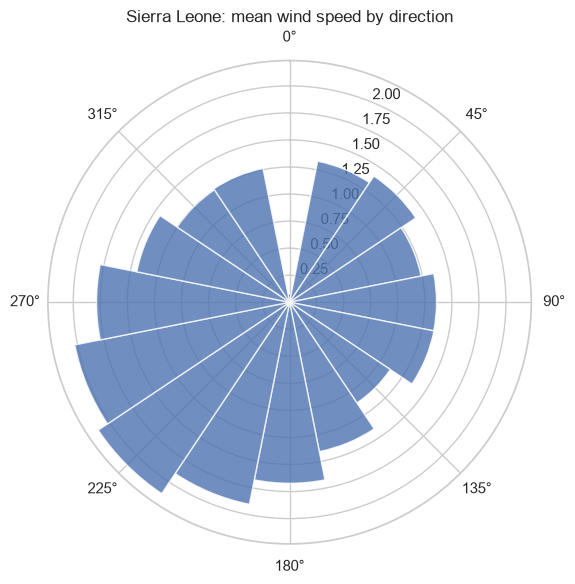

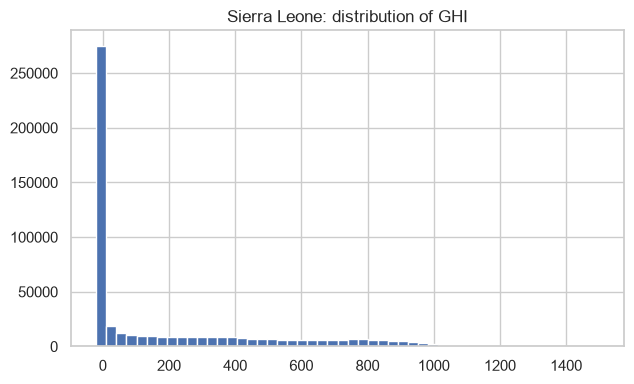

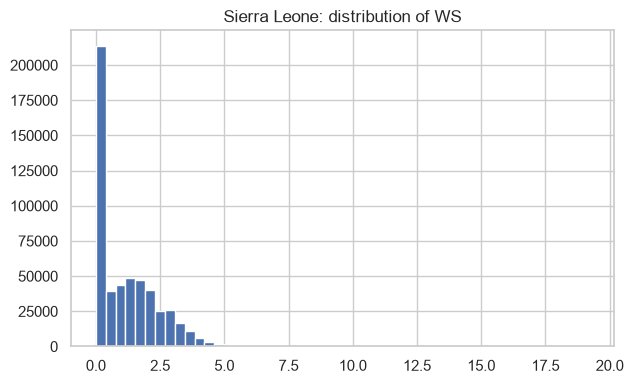

In [12]:
if "WD" in df_clean.columns and "WS" in df_clean.columns:
    wind = df_clean[["WD", "WS"]].dropna().copy()
    wind["direction_bin"] = (np.floor(wind["WD"] / 22.5) * 22.5) % 360
    wind_means = wind.groupby("direction_bin")["WS"].mean().sort_index()

    fig = plt.figure(figsize=(6, 6))
    ax = fig.add_subplot(111, projection="polar")
    ax.bar(np.deg2rad(wind_means.index.to_numpy()), wind_means.to_numpy(),
           width=np.deg2rad(22.5), alpha=0.8)
    ax.set_theta_zero_location("N")
    ax.set_theta_direction(-1)
    ax.set_title("Sierra Leone: mean wind speed by direction")
    plt.tight_layout()
    plt.savefig(OUTPUT_FIGURE_DIR / "sierraleone_wind_direction_radial.png", dpi=140)
    plt.show()
else:
    print("WD or WS is missing; radial plot skipped.")

for col in ["GHI", "WS"]:
    if col not in df_clean.columns:
        continue
    plt.figure(figsize=(6.5, 4))
    plt.hist(df_clean[col].dropna().to_numpy(), bins=50)
    plt.title("Sierra Leone: distribution of " + col)
    plt.tight_layout()
    plt.savefig(OUTPUT_FIGURE_DIR / ("sierraleone_" + col.lower() + "_histogram.png"), dpi=140)
    plt.show()

Temperature and humidity bubble chart

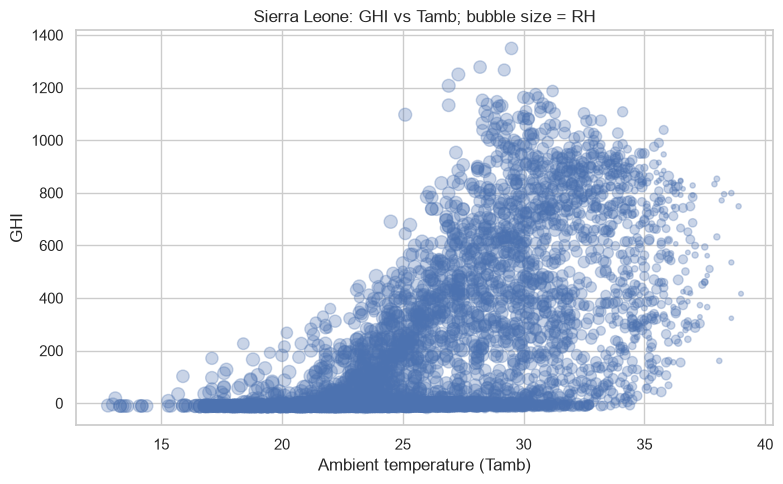

In [13]:
bubble_size_column = "RH" if "RH" in df_clean.columns else ("BP" if "BP" in df_clean.columns else None)
if all(c in df_clean.columns for c in ["GHI", "Tamb"]) and bubble_size_column:
    bubble_df = df_clean[["Tamb", "GHI", bubble_size_column]].dropna()
    if len(bubble_df) > 5000:
        bubble_df = bubble_df.sample(5000, random_state=42)

    size_values = bubble_df[bubble_size_column].clip(lower=0)
    size_range = size_values.max() - size_values.min()
    if pd.notna(size_range) and size_range > 0:
        bubble_sizes = 10 + 90 * (size_values - size_values.min()) / size_range
    else:
        bubble_sizes = np.full(len(bubble_df), 30)

    plt.figure(figsize=(8, 5))
    plt.scatter(bubble_df["Tamb"], bubble_df["GHI"], s=bubble_sizes, alpha=0.3)
    plt.xlabel("Ambient temperature (Tamb)")
    plt.ylabel("GHI")
    plt.title("Sierra Leone: GHI vs Tamb; bubble size = " + bubble_size_column)
    plt.tight_layout()
    plt.savefig(OUTPUT_FIGURE_DIR / "sierraleone_bubble_ghi_tamb.png", dpi=140)
    plt.show()
else:
    print("GHI, Tamb, or a bubble-size variable (RH/BP) is missing; bubble chart skipped.")

In [14]:
summary = {}
for col in ["GHI", "DNI", "DHI", "Tamb", "WS", "RH"]:
    if col in df_clean.columns:
        summary[col] = {
            "mean": df_clean[col].mean(),
            "median": df_clean[col].median(),
            "std": df_clean[col].std(),
            "min": df_clean[col].min(),
            "max": df_clean[col].max(),
        }

display(pd.DataFrame(summary).T.round(3))

if "GHI" in df_clean.columns:
    print(f"Mean GHI (all records): {df_clean['GHI'].mean():.2f} W/m²")
    daylight = df_clean.loc[df_clean["GHI"] > 0, "GHI"]
    print(f"Mean GHI where GHI > 0: {daylight.mean():.2f} W/m²")
if "Comments" in df_clean.columns:
    print(f"Comments missing: {df_clean['Comments'].isna().mean() * 100:.1f}%")

,mean,median,std,min,max
GHI,201.958,0.3,298.495,-19.5,1499.0
DNI,116.376,-0.1,218.653,-7.8,946.0
DHI,113.721,-0.1,158.946,-17.9,892.0
Tamb,26.319,25.3,4.399,12.3,39.9
WS,1.146,0.8,1.239,0.0,19.2
RH,79.449,85.4,20.521,9.9,100.0


Mean GHI (all records): 201.96 W/m²
Mean GHI where GHI > 0: 407.22 W/m²
Comments missing: 100.0%
